In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import os
import scipy.stats as st
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np


path = "C:/projects/Final Rat Trans Project Result2023/blindmolerat_rnaseqanalysis-2024/DMBA/Results_10092025_f2.5_p0.01_SELECTED/genesymbol/"
os.chdir(path)


def get_antilog(df_fold_change):
    df_fold_change.rename(columns={df_fold_change.columns[0]: "GeneSymbol", 
                                   df_fold_change.columns[1]: "GeneID"}, inplace=True)
    log2_fold_changes = df_fold_change['log2FoldChange']
    antilog_fold_changes = np.power(2, log2_fold_changes)
    df_fold_change['Antilog_FC'] = antilog_fold_changes   
    df_fold_change = df_fold_change.rename(columns = {'log2FoldChange': 'logFC'})
    df_fold_change = df_fold_change[['GeneSymbol', 'GeneID', 'logFC', 'Antilog_FC', 'padj']]  # 'logCPM', 
    return df_fold_change

In [2]:
spalax_wound_foldchange = pd.read_csv("S.control-S.wound/S.control-S.wound_genes.csv") 
#spalax_wound_foldchange = spalax_wound_foldchange.rename(columns = {'Unnamed: 0': 'GeneID'})
spalax_wound_foldchange = get_antilog(spalax_wound_foldchange)

mouse_wound_foldchange = pd.read_csv("MM.control-M.wound/MM.control-M.wound_genes.csv") 
#mouse_wound_foldchange = mouse_wound_foldchange.rename(columns = {'Unnamed: 0': 'GeneID'})
mouse_wound_foldchange = get_antilog(mouse_wound_foldchange)

spalax_scar_foldchange = pd.read_csv("S.control-S.scar/S.control-S.scar_genes.csv") 
#spalax_scar_foldchange = spalax_scar_foldchange.rename(columns = {'Unnamed: 0': 'GeneID'})
spalax_scar_foldchange = get_antilog(spalax_scar_foldchange)

mouse_scar_foldchange = pd.read_csv("MM.control-M.scar/MM.control-M.scar_genes.csv") 
#mouse_scar_foldchange = mouse_scar_foldchange.rename(columns = {'Unnamed: 0': 'GeneID'})
mouse_scar_foldchange = get_antilog(mouse_scar_foldchange)

In [3]:
spalax_wound_up_count = len(spalax_wound_foldchange[spalax_wound_foldchange['logFC'] > 0])
spalax_wound_down_count = len(spalax_wound_foldchange[spalax_wound_foldchange['logFC'] < 0])
spalax_scar_up_count = len(spalax_scar_foldchange[spalax_scar_foldchange['logFC'] > 0])
spalax_scar_down_count = len(spalax_scar_foldchange[spalax_scar_foldchange['logFC'] < 0])

mouse_wound_up_count = len(mouse_wound_foldchange[mouse_wound_foldchange['logFC'] > 0])
mouse_wound_down_count = len(mouse_wound_foldchange[mouse_wound_foldchange['logFC'] < 0])
mouse_scar_up_count = len(mouse_scar_foldchange[mouse_scar_foldchange['logFC']> 0])
mouse_scar_down_count = len(mouse_scar_foldchange[mouse_scar_foldchange['logFC'] < 0])

print(spalax_wound_up_count + spalax_wound_down_count)
print(spalax_scar_up_count + spalax_scar_down_count)
print(mouse_wound_up_count + mouse_wound_down_count)
print(mouse_scar_up_count + mouse_scar_down_count)

458
529
1041
1454


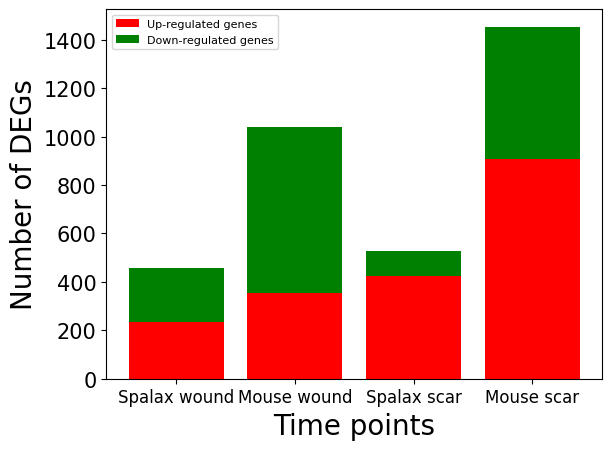

C:\Users\rahul\AppData\Local\Temp\ipykernel_15544\2285278060.py:44: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=violin_df, x='Group', y='logFC', palette=colors)


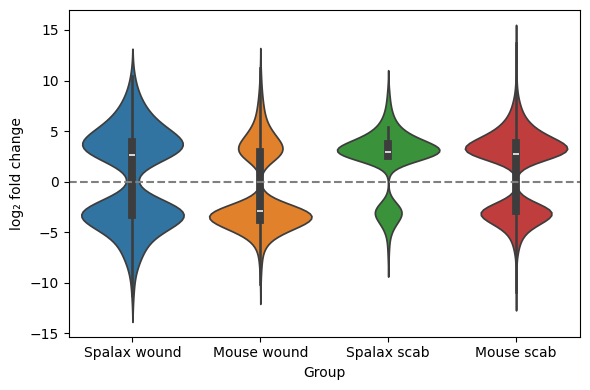

C:\Users\rahul\AppData\Local\Temp\ipykernel_15544\2285278060.py:54: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=violin_df, x='Group', y='logFC', palette=colors)


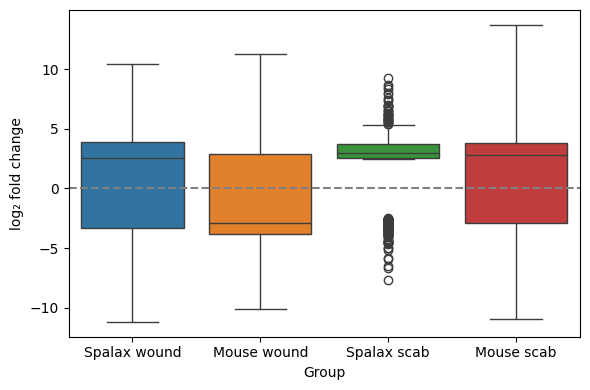

In [4]:
colors = {
    'Spalax wound': '#1f77b4',  # blue
    'Spalax scab': '#2ca02c',   # green
    'Mouse wound': '#ff7f0e',   # orange
    'Mouse scab': '#d62728'     # red
}

# create data
x = ['Spalax wound', 'Mouse wound', 'Spalax scar', 'Mouse scar']
y1 = np.array([spalax_wound_up_count, mouse_wound_up_count, spalax_scar_up_count, mouse_scar_up_count ])
y2 = np.array([spalax_wound_down_count, mouse_wound_down_count, spalax_scar_down_count, mouse_scar_down_count])

# plot bars in stack manner
plt.bar(x, y1, color='r')
plt.bar(x, y2, bottom=y1, color='g')
plt.xlabel("Time points", fontsize = 20)
plt.ylabel("Number of DEGs", fontsize = 20)
plt.legend(["Up-regulated genes", "Down-regulated genes"], fontsize = 8)
#plt.title("up/down-regulated DEGs in both species", fontsize = 20)
plt.xticks(fontsize=12)
plt.yticks(fontsize=15)
plt.savefig('upregulated_downregulated.jpg', format='jpeg', dpi=300, bbox_inches='tight')
plt.show()




# Build one dataframe for all 4 groups
violin_df = pd.DataFrame({
    'logFC': pd.concat([
        spalax_wound_foldchange['logFC'],        
        mouse_wound_foldchange['logFC'],
        spalax_scar_foldchange['logFC'],
        mouse_scar_foldchange['logFC']
    ], ignore_index=True),
    'Group': ['Spalax wound'] * len(spalax_wound_foldchange)
           + ['Mouse wound'] * len(mouse_wound_foldchange)
           + ['Spalax scab'] * len(spalax_scar_foldchange)
           + ['Mouse scab'] * len(mouse_scar_foldchange)
})

# Plot
plt.figure(figsize=(6, 4))
sns.violinplot(data=violin_df, x='Group', y='logFC', palette=colors)
plt.axhline(0, color='gray', linestyle='--')
# plt.title('Distribution of log₂ fold change across groups')
plt.ylabel('log₂ fold change')
plt.tight_layout()
plt.savefig('violin_logFC_groups.jpg', dpi=300)
plt.show()

# Plot
plt.figure(figsize=(6, 4))
sns.boxplot(data=violin_df, x='Group', y='logFC', palette=colors)
plt.axhline(0, color='gray', linestyle='--')
# plt.title('Distribution of log₂ fold change across groups')
plt.ylabel('log₂ fold change')
plt.tight_layout()
plt.savefig('box_logFC_groups.jpg', dpi=300)
plt.show()


### Kegg pathway maps

In [5]:
path = "C:/projects/Final Rat Trans Project Result2023/blindmolerat_rnaseqanalysis-2024/DMBA/Results_10092025_f2.5_p0.01_SELECTED/genesymbol/"
os.chdir(path)

def filter_by_qvalue(df: pd.DataFrame, threshold: float = 0.05) -> pd.DataFrame:
    """
    Filters a DataFrame to keep only rows where 'qvalue' is less than the given threshold.

    Parameters:
        df (pd.DataFrame): Input DataFrame with a 'qvalue' column.
        threshold (float): Threshold for filtering. Default is 0.05.

    Returns:
        pd.DataFrame: Filtered DataFrame.
    """
    if 'qvalue' not in df.columns:
        raise ValueError("The DataFrame must contain a 'qvalue' column.")
    
    return df[df['qvalue'] < threshold]

def filter_scab_q_value(df_scab, df_wound):
    return df_scab[
    df_scab['Description'].isin(
        list(df_wound.Description[0:20])
    )][['Description', 'qvalue']]


def reindex_df(df1, df2):
    # Set Description as index in df2
    df2_indexed = df2.set_index('Description')

    # Reindex df2 to match the order of df1['Description'], and fill missing q-values with 0
    df2_sorted = df2_indexed.reindex(df1['Description']).fillna(0).reset_index()

    # Ensure the column is named correctly (in case of case or spacing issues)
    df2_sorted.rename(columns={'qvalue': 'qvalue'}, inplace=True)  # optional, if name is inconsistent

    # Result: df2_sorted now has the same Description order as df1, with 0 qvalue where missing
    return df2_sorted


In [11]:
spalax_wound_pathways = pd.read_csv("../entrezID/S.control-S.wound/Kegg_pathway.csv.csv")
spalax_wound_pathways = spalax_wound_pathways.drop(columns = ['Unnamed: 0'])
spalax_wound_pathways = filter_by_qvalue(spalax_wound_pathways)
spalax_scab_pathways = pd.read_csv("../entrezID/S.control-S.scar/Kegg_pathway.csv.csv")
spalax_scab_pathways = spalax_scab_pathways.drop(columns = ['Unnamed: 0'])
spalax_scab_pathways = filter_by_qvalue(spalax_scab_pathways)

# ---------------------------------
mouse_wound_pathways = pd.read_csv("../entrezID/MM.control-M.wound/Kegg_pathway_Mouse.csv.csv")
mouse_wound_pathways = mouse_wound_pathways.drop(columns = ['Unnamed: 0'])
mouse_wound_pathways = filter_by_qvalue(mouse_wound_pathways)
mouse_scab_pathways = pd.read_csv("../entrezID/MM.control-M.scar/Kegg_pathway.csv.csv")
mouse_scab_pathways = mouse_scab_pathways.drop(columns = ['Unnamed: 0'])
mouse_scab_pathways = filter_by_qvalue(mouse_scab_pathways)


### Pathway intensity at wound and scab stages

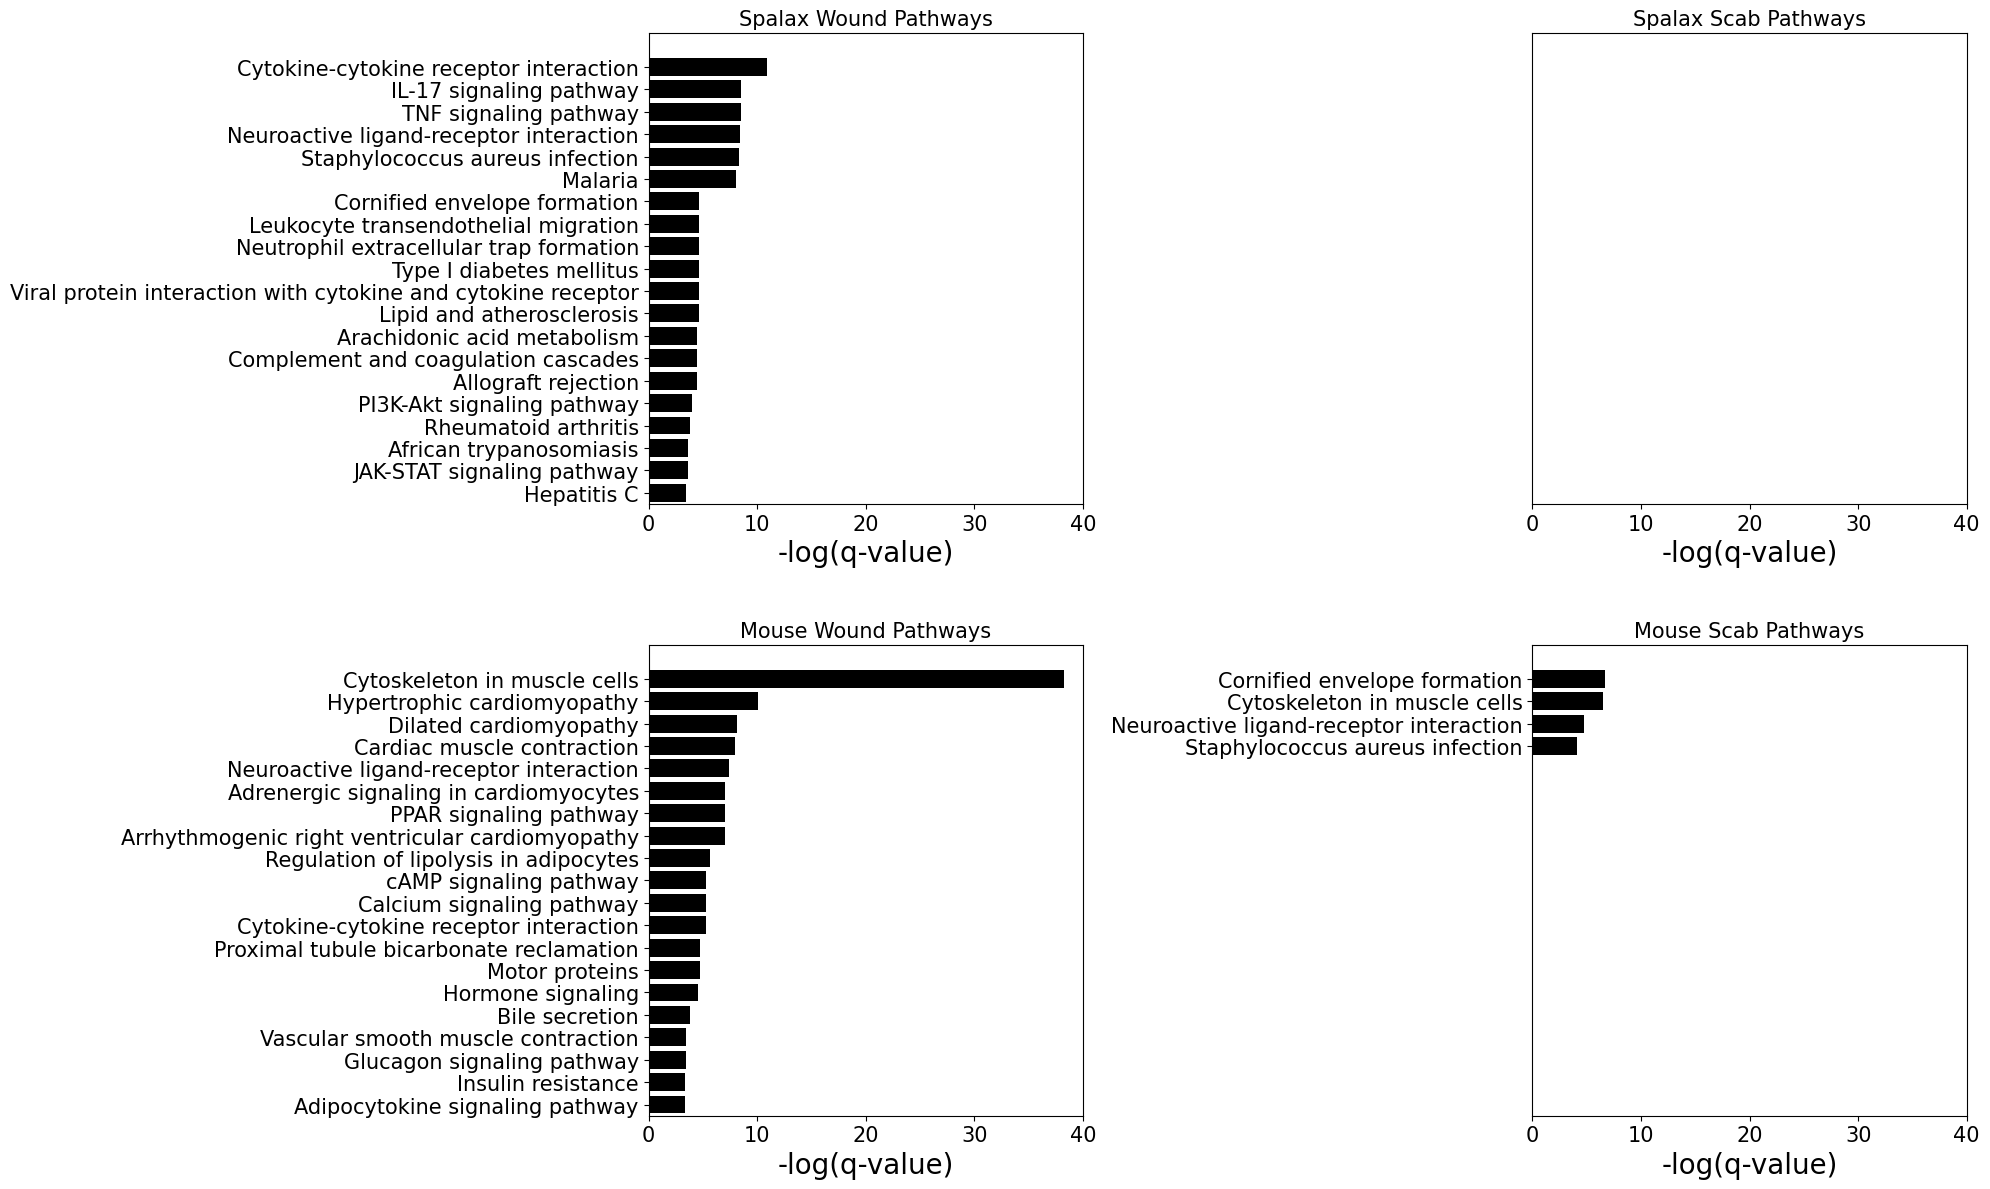

In [12]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

def plot_pathway_intensity(ax, timepoint, title):
    pathways = timepoint.iloc[0:20][['Description', 'qvalue', 'Count']]
    pathways['Description'] = [p.split(' - Mus musculus (house mouse)')[0] for p in pathways['Description'].values]
    pathways['qvalue'] = -np.log(pathways['qvalue'])

    n_display = len(pathways)
    y_pos = np.arange(n_display)[::-1] + (20 - n_display)  # Shift bars to top of 10-slot space

    ax.barh(y_pos, pathways.qvalue, align='center', color='black', height=0.8)
    ax.set_yticks(y_pos)
    ax.set_yticklabels(pathways.Description, fontsize=15)
    ax.set_title(title, fontsize=15)
    ax.set_xlim(0, 40)
    ax.set_ylim(-0.5, 20.5)  # Reserve space for 10
    ax.set_xlabel('-log(q-value)', fontsize=20)
    ax.tick_params(axis='x', labelsize=15)




# Create a 2x2 subplot figure
fig, axs = plt.subplots(2, 2, figsize=(20, 12))

# Plot each pathway intensity on its respective subplot
plot_pathway_intensity(axs[0, 0], spalax_wound_pathways, 'Spalax Wound Pathways')
plot_pathway_intensity(axs[0, 1], spalax_scab_pathways, 'Spalax Scab Pathways')
plot_pathway_intensity(axs[1, 0], mouse_wound_pathways, 'Mouse Wound Pathways')
plot_pathway_intensity(axs[1, 1], mouse_scab_pathways, 'Mouse Scab Pathways')

# Adjust layout for better spacing
plt.tight_layout()
plt.subplots_adjust(hspace=0.3)  # Increase the space between rows

# Show the plot
plt.show()


## Up regulated analysis



                                         Description        qvalue
0  TNF signaling pathway - Mus musculus (house mo...  1.170330e-07
1  IL-17 signaling pathway - Mus musculus (house ...  1.739037e-07
2  Cytokine-cytokine receptor interaction - Mus m...  2.460127e-07
3               Malaria - Mus musculus (house mouse)  2.749169e-06
4  Staphylococcus aureus infection - Mus musculus...  1.053602e-05
5  Neutrophil extracellular trap formation - Mus ...  4.717402e-05
6  Lipid and atherosclerosis - Mus musculus (hous...  4.717402e-05
7  Type I diabetes mellitus - Mus musculus (house...  5.594713e-04
8  Rheumatoid arthritis - Mus musculus (house mouse)  5.594713e-04
9  Viral protein interaction with cytokine and cy...  7.275907e-04
                                         Description    qvalue
0  TNF signaling pathway - Mus musculus (house mo...  0.000000
1  IL-17 signaling pathway - Mus musculus (house ...  0.049873
2  Cytokine-cytokine receptor interaction - Mus m...  0.000000
3        

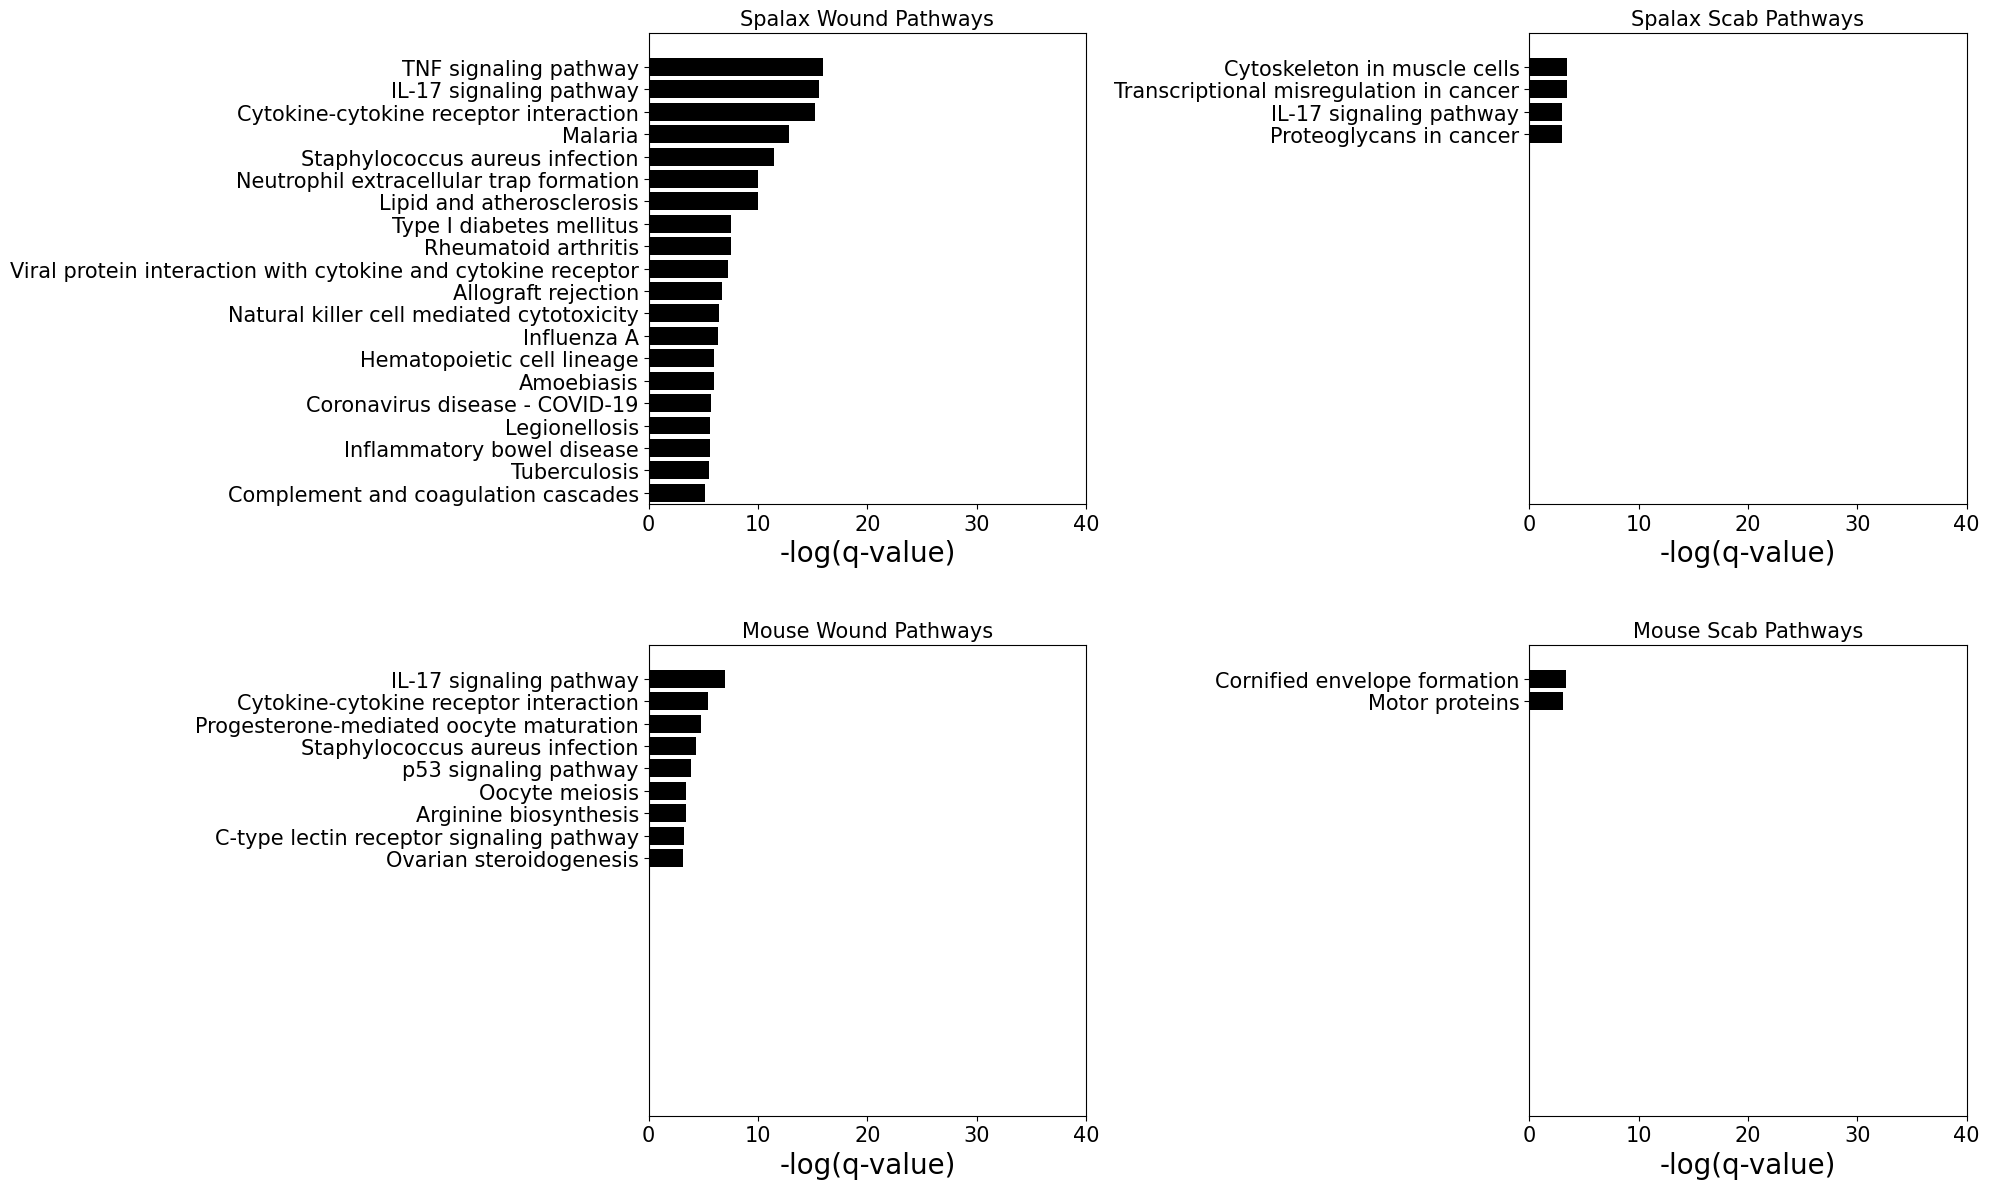

In [21]:
def plot_pathway_intensity(ax, timepoint, title):
    pathways = timepoint.iloc[0:20][['Description', 'qvalue', 'Count']]
    pathways['Description'] = [p.split(' - Mus musculus (house mouse)')[0] for p in pathways['Description'].values]
    pathways['qvalue'] = -np.log(pathways['qvalue'])

    n_display = len(pathways)
    y_pos = np.arange(n_display)[::-1] + (20 - n_display)  # Shift bars to top of 10-slot space

    ax.barh(y_pos, pathways.qvalue, align='center', color='black', height=0.8)
    ax.set_yticks(y_pos)
    ax.set_yticklabels(pathways.Description, fontsize=15)
    ax.set_title(title, fontsize=15)
    ax.set_xlim(0, 40)
    ax.set_ylim(-0.5, 20.5)  # Reserve space for 10
    ax.set_xlabel('-log(q-value)', fontsize=20)
    ax.tick_params(axis='x', labelsize=15)
    
spalax_wound_pathways = pd.read_csv("../entrezID/S.control-S.wound/Kegg_pathway.csvUp.csv")
spalax_wound_pathways = spalax_wound_pathways.drop(columns = ['Unnamed: 0'])
spalax_wound_pathways = filter_by_qvalue(spalax_wound_pathways)
spalax_scab_pathways = pd.read_csv("../entrezID/S.control-S.scar/Kegg_pathway.csvUp.csv")
spalax_scab_pathways = spalax_scab_pathways.drop(columns = ['Unnamed: 0'])
spalax_scab_pathways = filter_by_qvalue(spalax_scab_pathways)

spalax_wound_pathways_scab = filter_scab_q_value(spalax_scab_pathways, spalax_wound_pathways)
spalax_wound_pathways_scab = reindex_df(spalax_wound_pathways[["Description", "qvalue"]].head(20), spalax_wound_pathways_scab)
print("\n")
print(spalax_wound_pathways[["Description", "qvalue"]].head(10))
print(spalax_wound_pathways_scab[["Description", "qvalue"]].head(10))

# ---------------------------------
mouse_wound_pathways = pd.read_csv("../entrezID/MM.control-M.wound/Kegg_pathway.csvUp.csv")
mouse_wound_pathways = mouse_wound_pathways.drop(columns = ['Unnamed: 0'])
mouse_wound_pathways = filter_by_qvalue(mouse_wound_pathways)
mouse_scab_pathways = pd.read_csv("../entrezID/MM.control-M.scar/Kegg_pathway.csvUp.csv")
mouse_scab_pathways = mouse_scab_pathways.drop(columns = ['Unnamed: 0'])
mouse_scab_pathways = filter_by_qvalue(mouse_scab_pathways)

mouse_wound_pathways_scab = filter_scab_q_value(mouse_scab_pathways, mouse_wound_pathways)
mouse_wound_pathways_scab = reindex_df(mouse_wound_pathways[["Description", "qvalue"]].head(20), mouse_wound_pathways_scab)
print("\n")
print(mouse_wound_pathways[["Description", "qvalue"]].head(10))
print(mouse_wound_pathways_scab.head(10))

# Create a 2x2 subplot figure
fig, axs = plt.subplots(2, 2, figsize=(20, 12))

# Plot each pathway intensity on its respective subplot
plot_pathway_intensity(axs[0, 0], spalax_wound_pathways, 'Spalax Wound Pathways')
plot_pathway_intensity(axs[0, 1], spalax_scab_pathways, 'Spalax Scab Pathways')
plot_pathway_intensity(axs[1, 0], mouse_wound_pathways, 'Mouse Wound Pathways')
plot_pathway_intensity(axs[1, 1], mouse_scab_pathways, 'Mouse Scab Pathways')

# Adjust layout for better spacing
plt.tight_layout()
plt.subplots_adjust(hspace=0.3)  # Increase the space between rows

# Show the plot
plt.show()

### Down regulated analysis



                                         Description    qvalue
0  Cornified envelope formation - Mus musculus (h...  0.000089
1  Neuroactive ligand-receptor interaction - Mus ...  0.001302
2  Sphingolipid metabolism - Mus musculus (house ...  0.008941
3  Virion - Hepatitis viruses - Mus musculus (hou...  0.011006
4  Arachidonic acid metabolism - Mus musculus (ho...  0.012774
5  AMPK signaling pathway - Mus musculus (house m...  0.044915
6        Tight junction - Mus musculus (house mouse)  0.044915
7  Proximal tubule bicarbonate reclamation - Mus ...  0.044915
8  PPAR signaling pathway - Mus musculus (house m...  0.044915
9  Neuroactive ligand signaling - Mus musculus (h...  0.044915
                                         Description  qvalue
0  Cornified envelope formation - Mus musculus (h...     0.0
1  Neuroactive ligand-receptor interaction - Mus ...     0.0
2  Sphingolipid metabolism - Mus musculus (house ...     0.0
3  Virion - Hepatitis viruses - Mus musculus (hou...     0.0


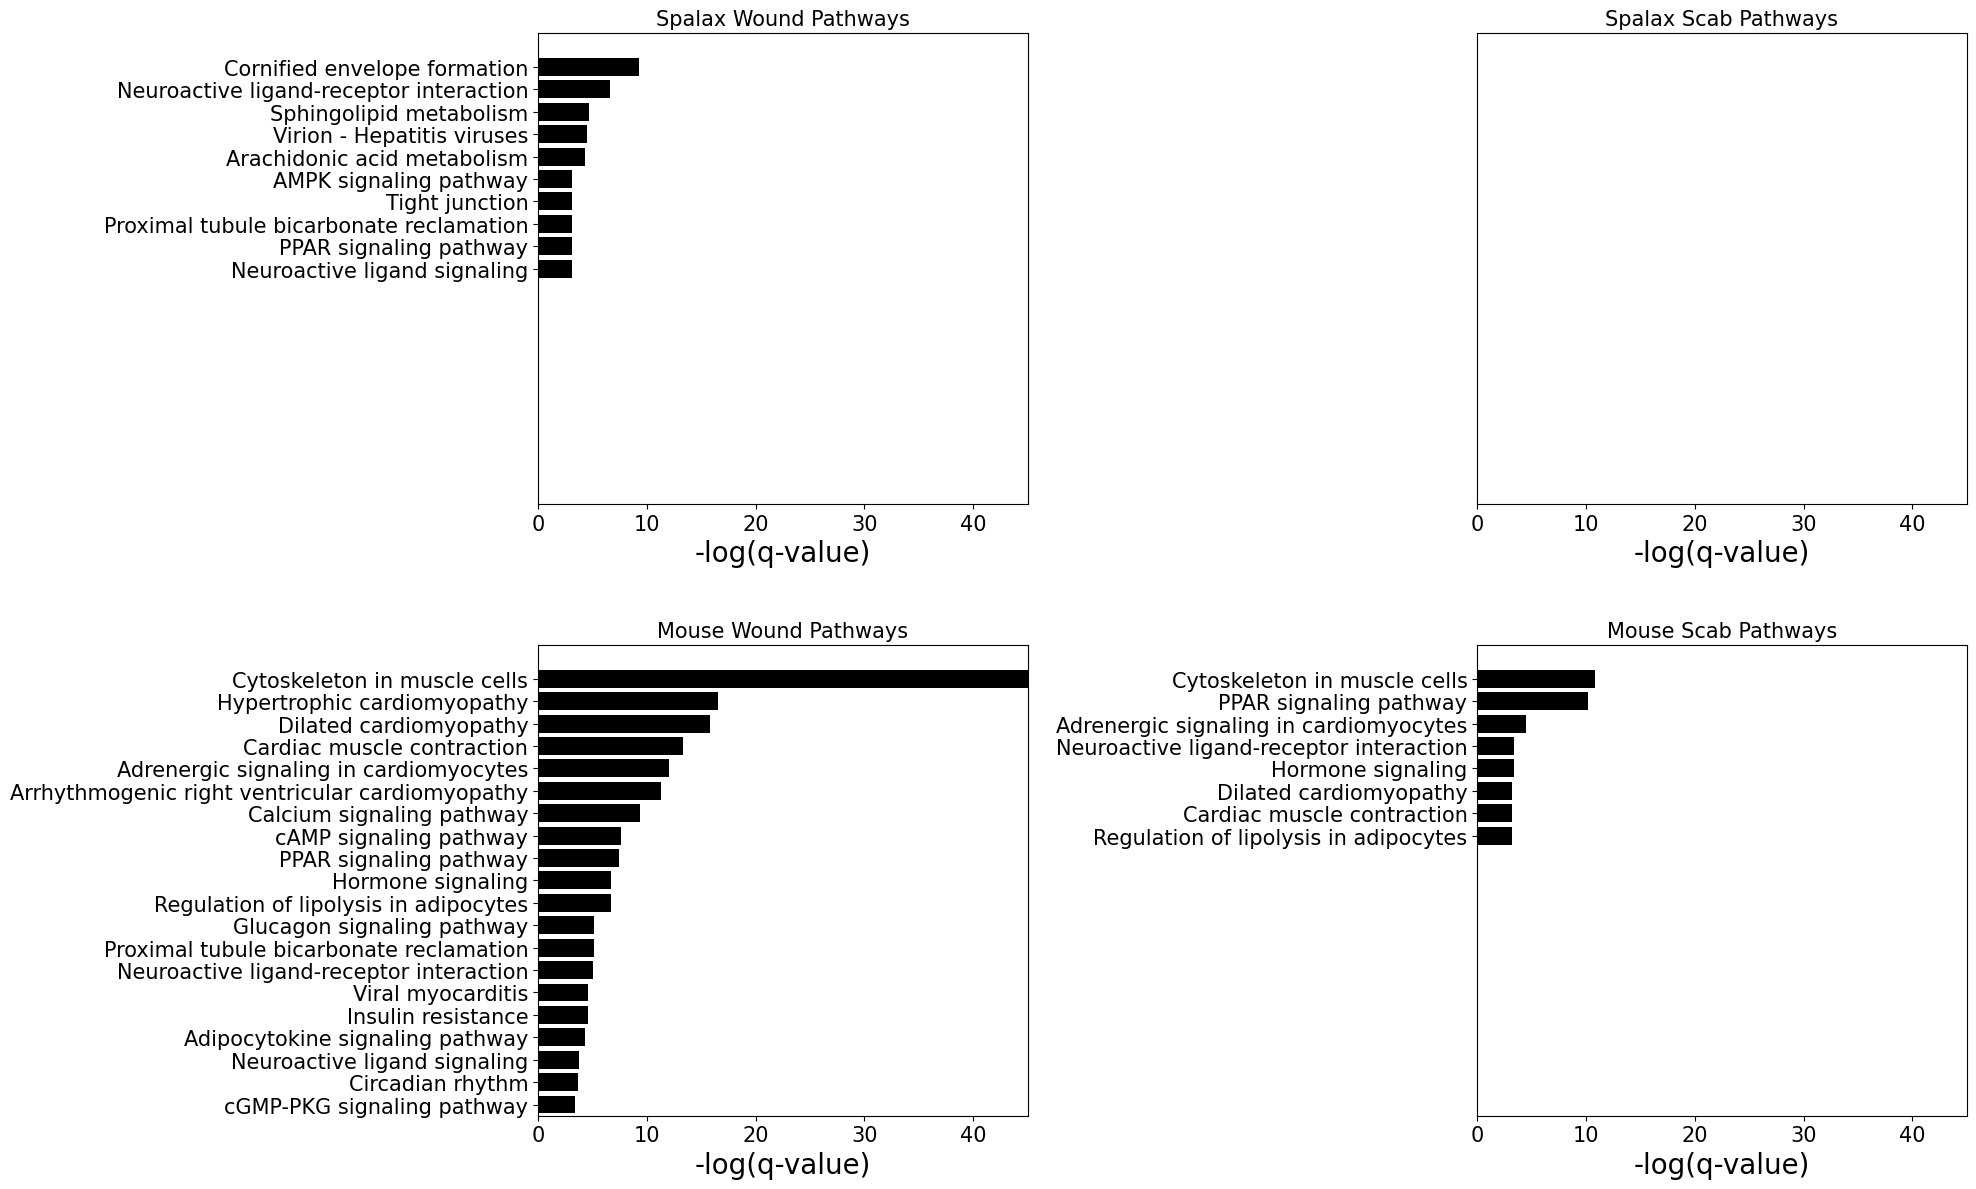

In [22]:
def plot_pathway_intensity(ax, timepoint, title):
    pathways = timepoint.iloc[0:20][['Description', 'qvalue', 'Count']]
    pathways['Description'] = [p.split(' - Mus musculus (house mouse)')[0] for p in pathways['Description'].values]
    pathways['qvalue'] = -np.log(pathways['qvalue'])

    n_display = len(pathways)
    y_pos = np.arange(n_display)[::-1] + (20 - n_display)  # Shift bars to top of 10-slot space

    ax.barh(y_pos, pathways.qvalue, align='center', color='black', height=0.8)
    ax.set_yticks(y_pos)
    ax.set_yticklabels(pathways.Description, fontsize=15)
    ax.set_title(title, fontsize=15)
    ax.set_xlim(0, 45)
    ax.set_ylim(-0.5, 20.5)  # Reserve space for 10
    ax.set_xlabel('-log(q-value)', fontsize=20)
    ax.tick_params(axis='x', labelsize=15)
    
spalax_wound_pathways = pd.read_csv("../entrezID/S.control-S.wound/Kegg_pathway.csvDown.csv")
spalax_wound_pathways = spalax_wound_pathways.drop(columns = ['Unnamed: 0'])
spalax_wound_pathways = filter_by_qvalue(spalax_wound_pathways)
spalax_scab_pathways = pd.read_csv("../entrezID/S.control-S.scar/Kegg_pathway.csvDown.csv")
spalax_scab_pathways = spalax_scab_pathways.drop(columns = ['Unnamed: 0'])
spalax_scab_pathways = filter_by_qvalue(spalax_scab_pathways)

spalax_wound_pathways_scab = filter_scab_q_value(spalax_scab_pathways, spalax_wound_pathways)
spalax_wound_pathways_scab = reindex_df(spalax_wound_pathways[["Description", "qvalue"]].head(20), spalax_wound_pathways_scab)
print("\n")
print(spalax_wound_pathways[["Description", "qvalue"]].head(10))
print(spalax_wound_pathways_scab[["Description", "qvalue"]].head(10))

# ---------------------------------
mouse_wound_pathways = pd.read_csv("../entrezID/MM.control-M.wound/Kegg_pathway.csvDown.csv")
mouse_wound_pathways = mouse_wound_pathways.drop(columns = ['Unnamed: 0'])
mouse_wound_pathways = filter_by_qvalue(mouse_wound_pathways)
mouse_scab_pathways = pd.read_csv("../entrezID/MM.control-M.scar/Kegg_pathway.csvDown.csv")
mouse_scab_pathways = mouse_scab_pathways.drop(columns = ['Unnamed: 0'])
mouse_scab_pathways = filter_by_qvalue(mouse_scab_pathways)

mouse_wound_pathways_scab = filter_scab_q_value(mouse_scab_pathways, mouse_wound_pathways)
mouse_wound_pathways_scab = reindex_df(mouse_wound_pathways[["Description", "qvalue"]].head(20), mouse_wound_pathways_scab)
print("\n")
print(mouse_wound_pathways[["Description", "qvalue"]].head(10))
print(mouse_wound_pathways_scab.head(10))

# Create a 2x2 subplot figure
fig, axs = plt.subplots(2, 2, figsize=(20, 12))

# Plot each pathway intensity on its respective subplot
plot_pathway_intensity(axs[0, 0], spalax_wound_pathways, 'Spalax Wound Pathways')
plot_pathway_intensity(axs[0, 1], spalax_scab_pathways, 'Spalax Scab Pathways')
plot_pathway_intensity(axs[1, 0], mouse_wound_pathways, 'Mouse Wound Pathways')
plot_pathway_intensity(axs[1, 1], mouse_scab_pathways, 'Mouse Scab Pathways')

# Adjust layout for better spacing
plt.tight_layout()
plt.subplots_adjust(hspace=0.3)  # Increase the space between rows

# Show the plot
plt.show()

### BP analysis

In [ ]:
spalax_wound_bp = pd.read_csv("../entrezID/S.control-S.wound/GeneOntologyBP.csv")
spalax_wound_bp = spalax_wound_bp.drop(columns = ['Unnamed: 0'])
spalax_wound_bp = filter_by_qvalue(spalax_wound_bp)
spalax_scab_bp = pd.read_csv("../entrezID/S.control-S.scar/GeneOntologyBP.csv")
spalax_scab_bp = spalax_scab_bp.drop(columns = ['Unnamed: 0'])
spalax_scab_bp = filter_by_qvalue(spalax_scab_bp)

mouse_wound_bp = pd.read_csv("../entrezID/MM.control-M.wound/GeneOntologyBP.csv")
mouse_wound_bp = mouse_wound_bp.drop(columns = ['Unnamed: 0'])
mouse_wound_bp = filter_by_qvalue(mouse_wound_bp)
mouse_scab_bp = pd.read_csv("../entrezID/MM.control-M.scar/GeneOntologyBP.csv")
mouse_scab_bp = mouse_scab_bp.drop(columns = ['Unnamed: 0'])
mouse_scab_bp = filter_by_qvalue(mouse_scab_bp)



                                  Description        qvalue
0                       response to bacterium  2.779355e-14
1              regulation of defense response  1.480918e-09
2         regulation of inflammatory response  4.212593e-09
3                      innate immune response  1.799666e-08
4                         leukocyte migration  1.816392e-08
5  positive regulation of cytokine production  1.880035e-08
6    response to molecule of bacterial origin  6.281932e-08
7              antimicrobial humoral response  1.202848e-07
8     positive regulation of defense response  1.644673e-07
9              response to lipopolysaccharide  1.676178e-07
                                  Description  qvalue
0                       response to bacterium     0.0
1              regulation of defense response     0.0
2         regulation of inflammatory response     0.0
3                      innate immune response     0.0
4                         leukocyte migration     0.0
5  positive re

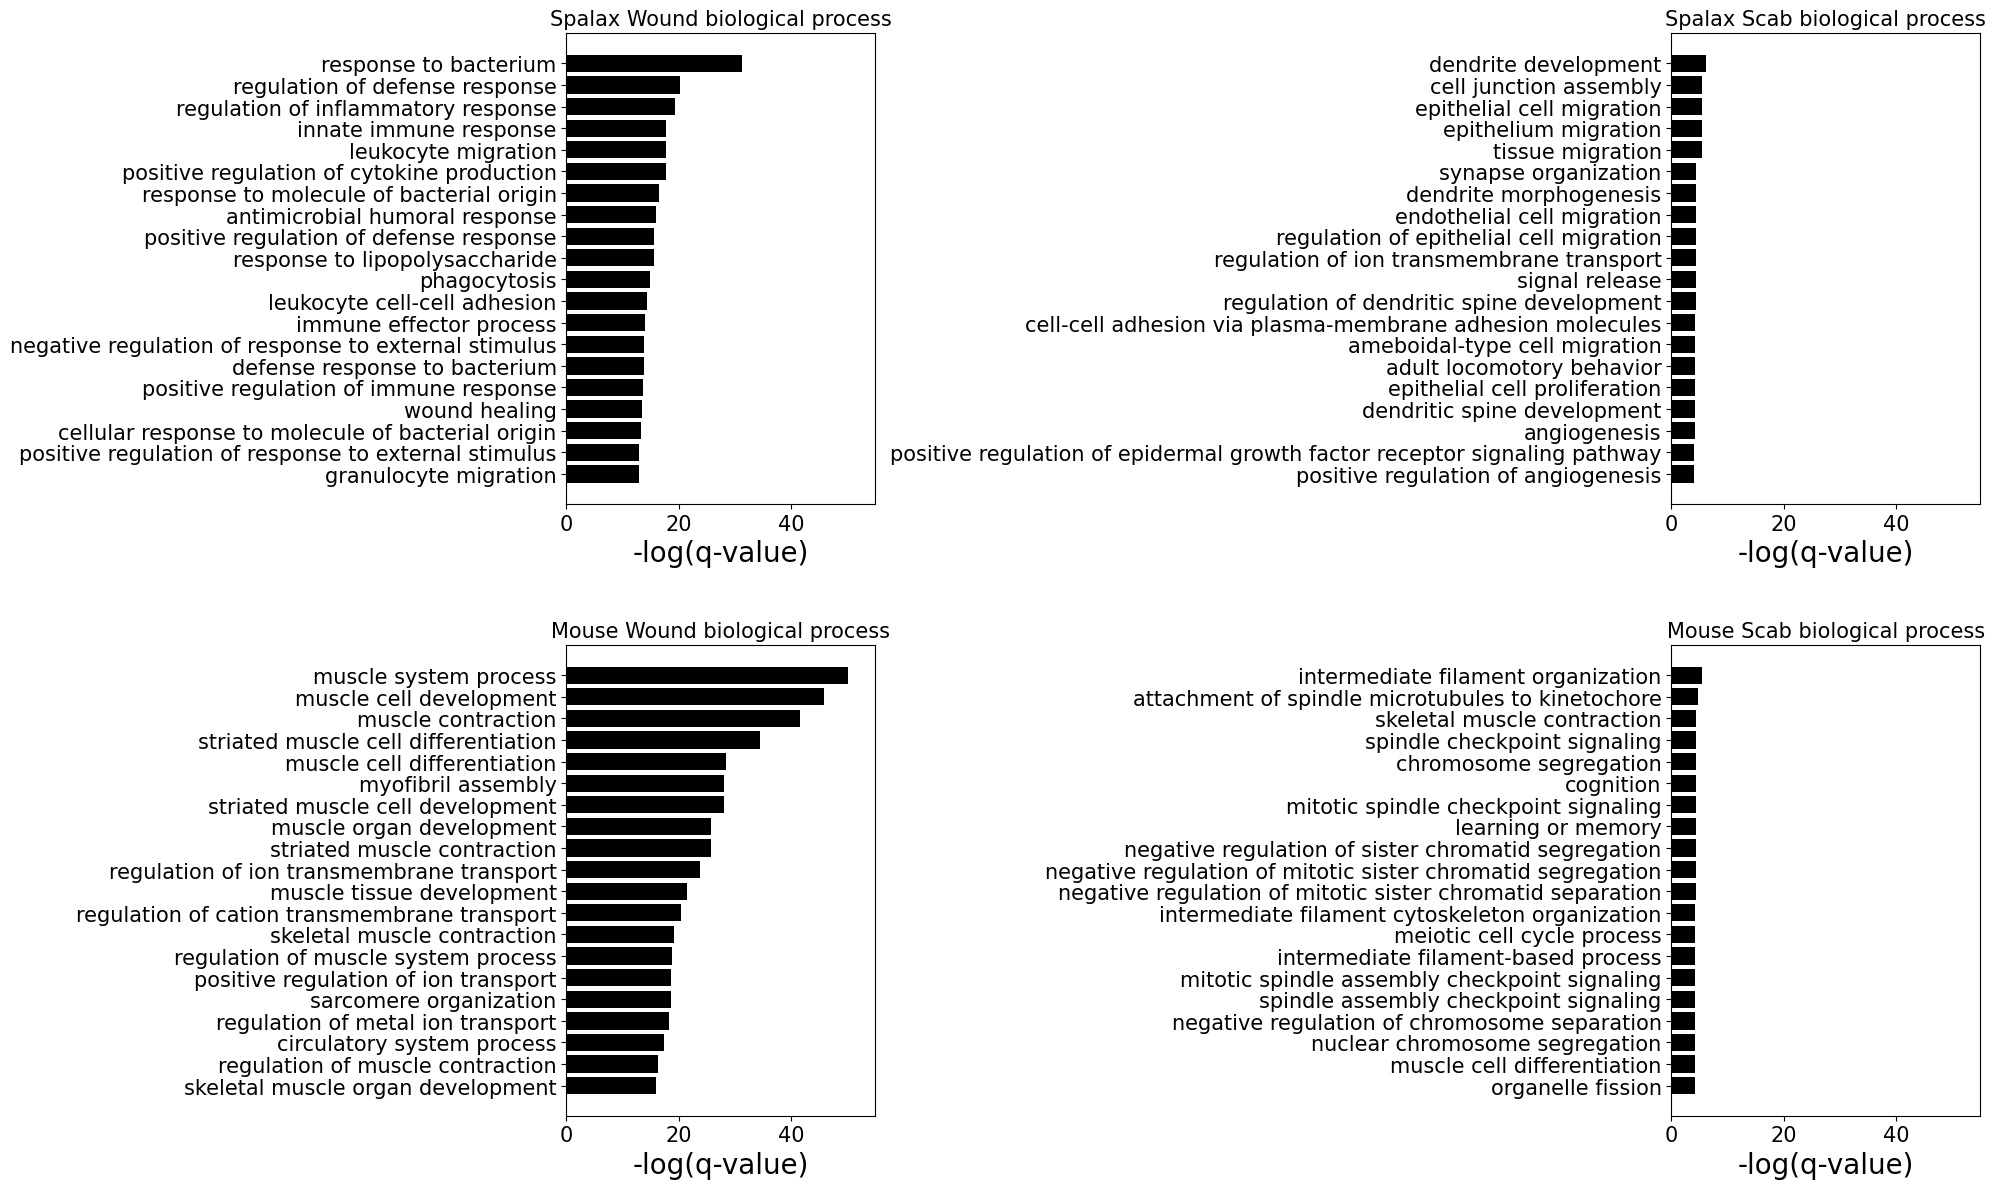

In [25]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

def plot_pathway_intensity(ax, timepoint, title):
    pathways = timepoint.iloc[0:20][['Description', 'qvalue']]
    pathways['Description'] = [p.split(' - Mus musculus (house mouse)')[0] for p in pathways['Description'].values]
    pathways['qvalue'] = -np.log(pathways['qvalue'])

    y_pos = np.arange(len(pathways))[::-1]
    ax.barh(y_pos, pathways.qvalue, align='center', color='black')
    ax.set_yticks(y_pos)
    ax.set_yticklabels(pathways.Description, fontsize=15)  # Increase y tick label size
    ax.set_title(title, fontsize=15)
    ax.set_xlim(0, 55)
    ax.set_xlabel('-log(q-value)', fontsize=20)
    ax.tick_params(axis='x', labelsize=15)  # Increase x tick label size


# Create a 2x2 subplot figure
fig, axs = plt.subplots(2, 2, figsize=(20, 12))

# Plot each pathway intensity on its respective subplot
plot_pathway_intensity(axs[0, 0], spalax_wound_bp, 'Spalax Wound biological process')
plot_pathway_intensity(axs[0, 1], spalax_scab_bp, 'Spalax Scab biological process')
plot_pathway_intensity(axs[1, 0], mouse_wound_bp, 'Mouse Wound biological process')
plot_pathway_intensity(axs[1, 1], mouse_scab_bp, 'Mouse Scab biological process')

# Adjust layout for better spacing
plt.tight_layout()
plt.subplots_adjust(hspace=0.3)  # Increase the space between rows

# Show the plot
plt.show()


c:\Users\rahul\anaconda3\envs\gene_disease\lib\site-packages\pandas\core\arraylike.py:364: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


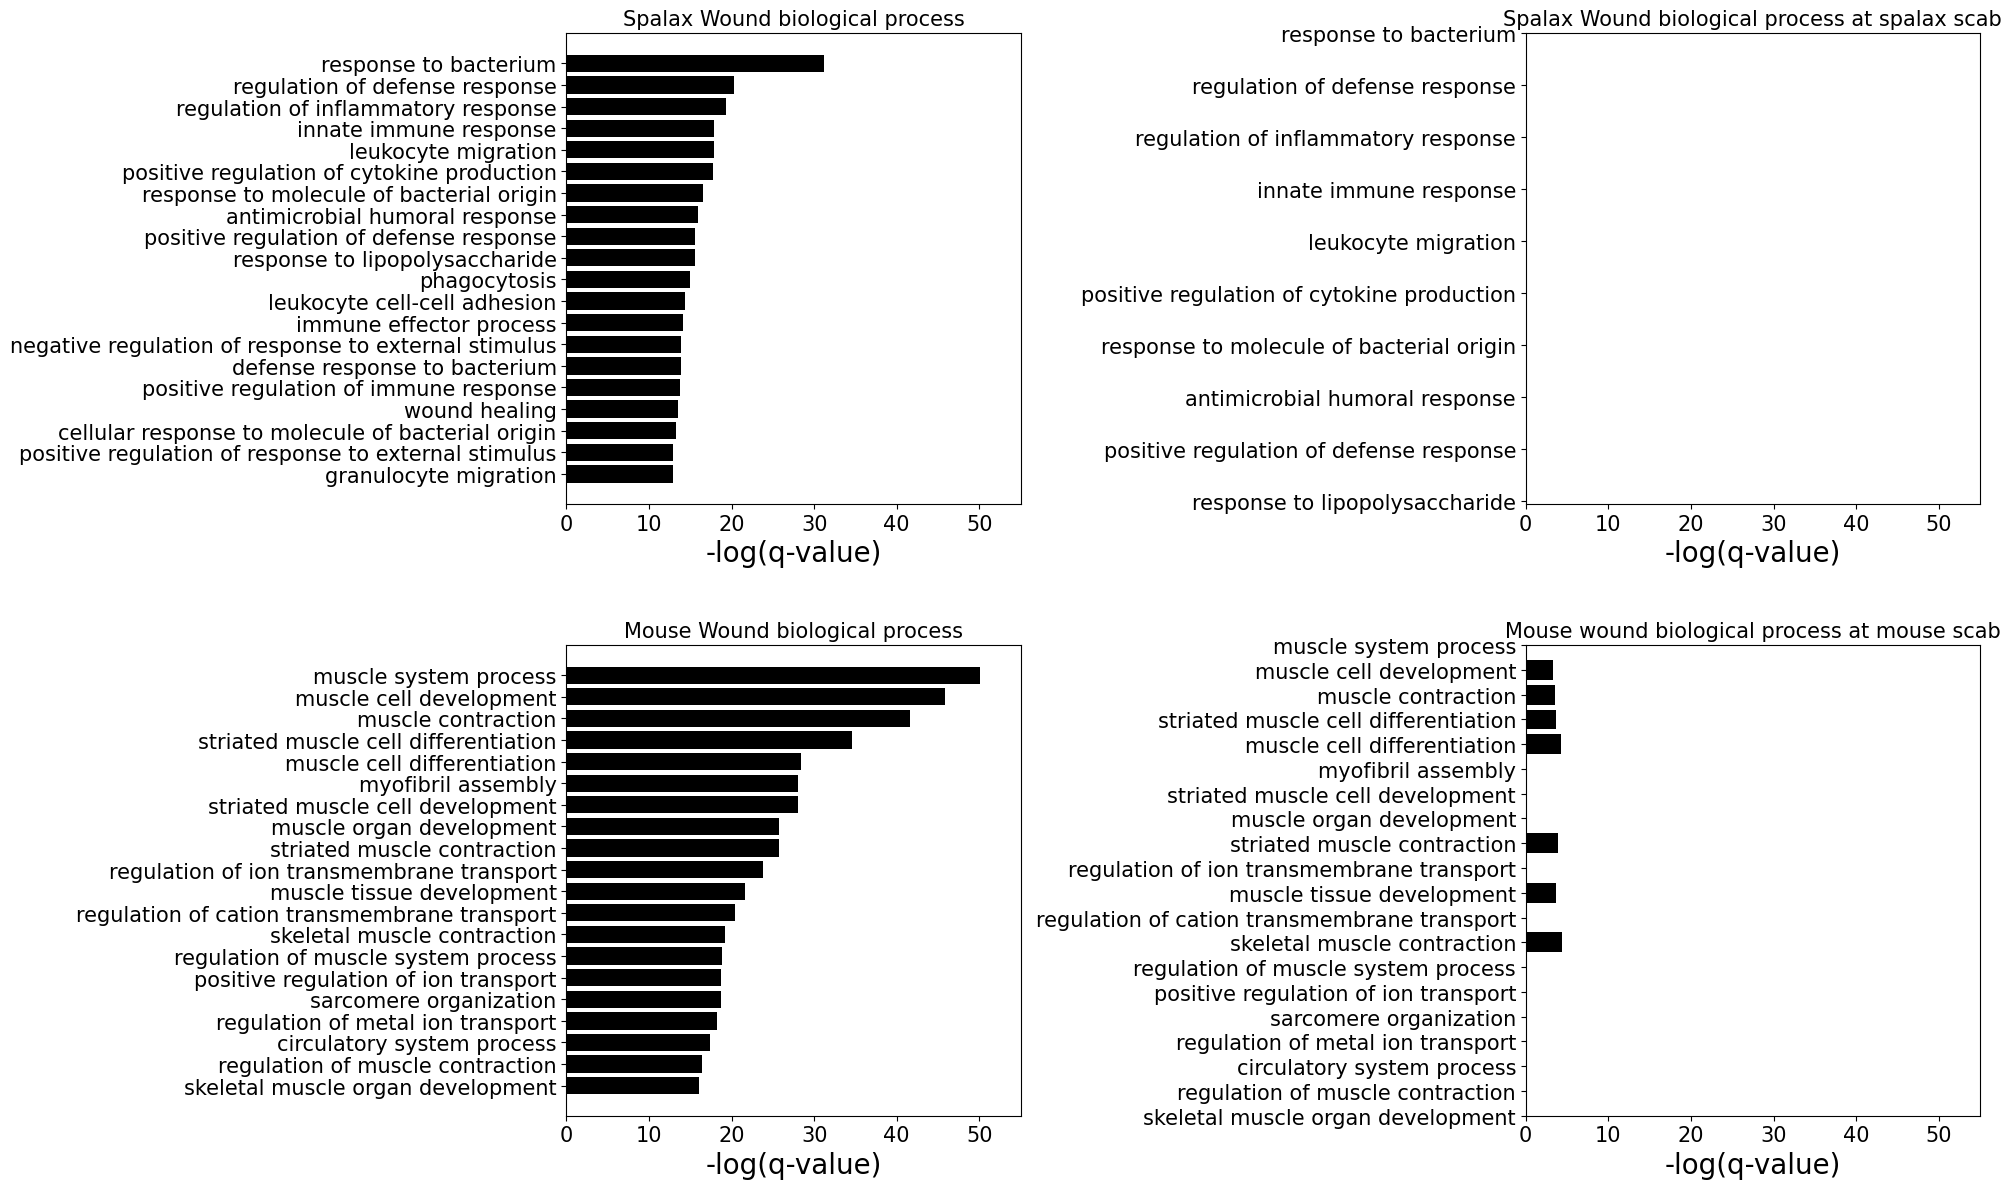

In [26]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Create a 2x2 subplot figure
fig, axs = plt.subplots(2, 2, figsize=(20, 12))

# Plot each pathway intensity on its respective subplot
plot_pathway_intensity(axs[0, 0], spalax_wound_bp, 'Spalax Wound biological process')
plot_pathway_intensity(axs[0, 1], spalax_wound_bp_scab, 'Spalax Wound biological process at spalax scab')
plot_pathway_intensity(axs[1, 0], mouse_wound_bp, 'Mouse Wound biological process')
plot_pathway_intensity(axs[1, 1], mouse_wound_bp_scab, 'Mouse wound biological process at mouse scab')

# Adjust layout for better spacing
plt.tight_layout()
plt.subplots_adjust(hspace=0.3)  # Increase the space between rows

# Show the plot
plt.show()


### Upregulated analysis



                                  Description        qvalue
0                       response to bacterium  1.559174e-16
1  positive regulation of cytokine production  5.578645e-14
2                      innate immune response  1.959525e-13
3     positive regulation of defense response  1.154135e-12
4              regulation of defense response  1.154135e-12
5    response to molecule of bacterial origin  1.154135e-12
6      positive regulation of immune response  1.154135e-12
7                         leukocyte migration  1.449939e-12
8              response to lipopolysaccharide  9.726893e-12
9         regulation of inflammatory response  9.726893e-12
                                  Description    qvalue
0                       response to bacterium  0.000000
1  positive regulation of cytokine production  0.029356
2                      innate immune response  0.000000
3     positive regulation of defense response  0.000000
4              regulation of defense response  0.000000
5 

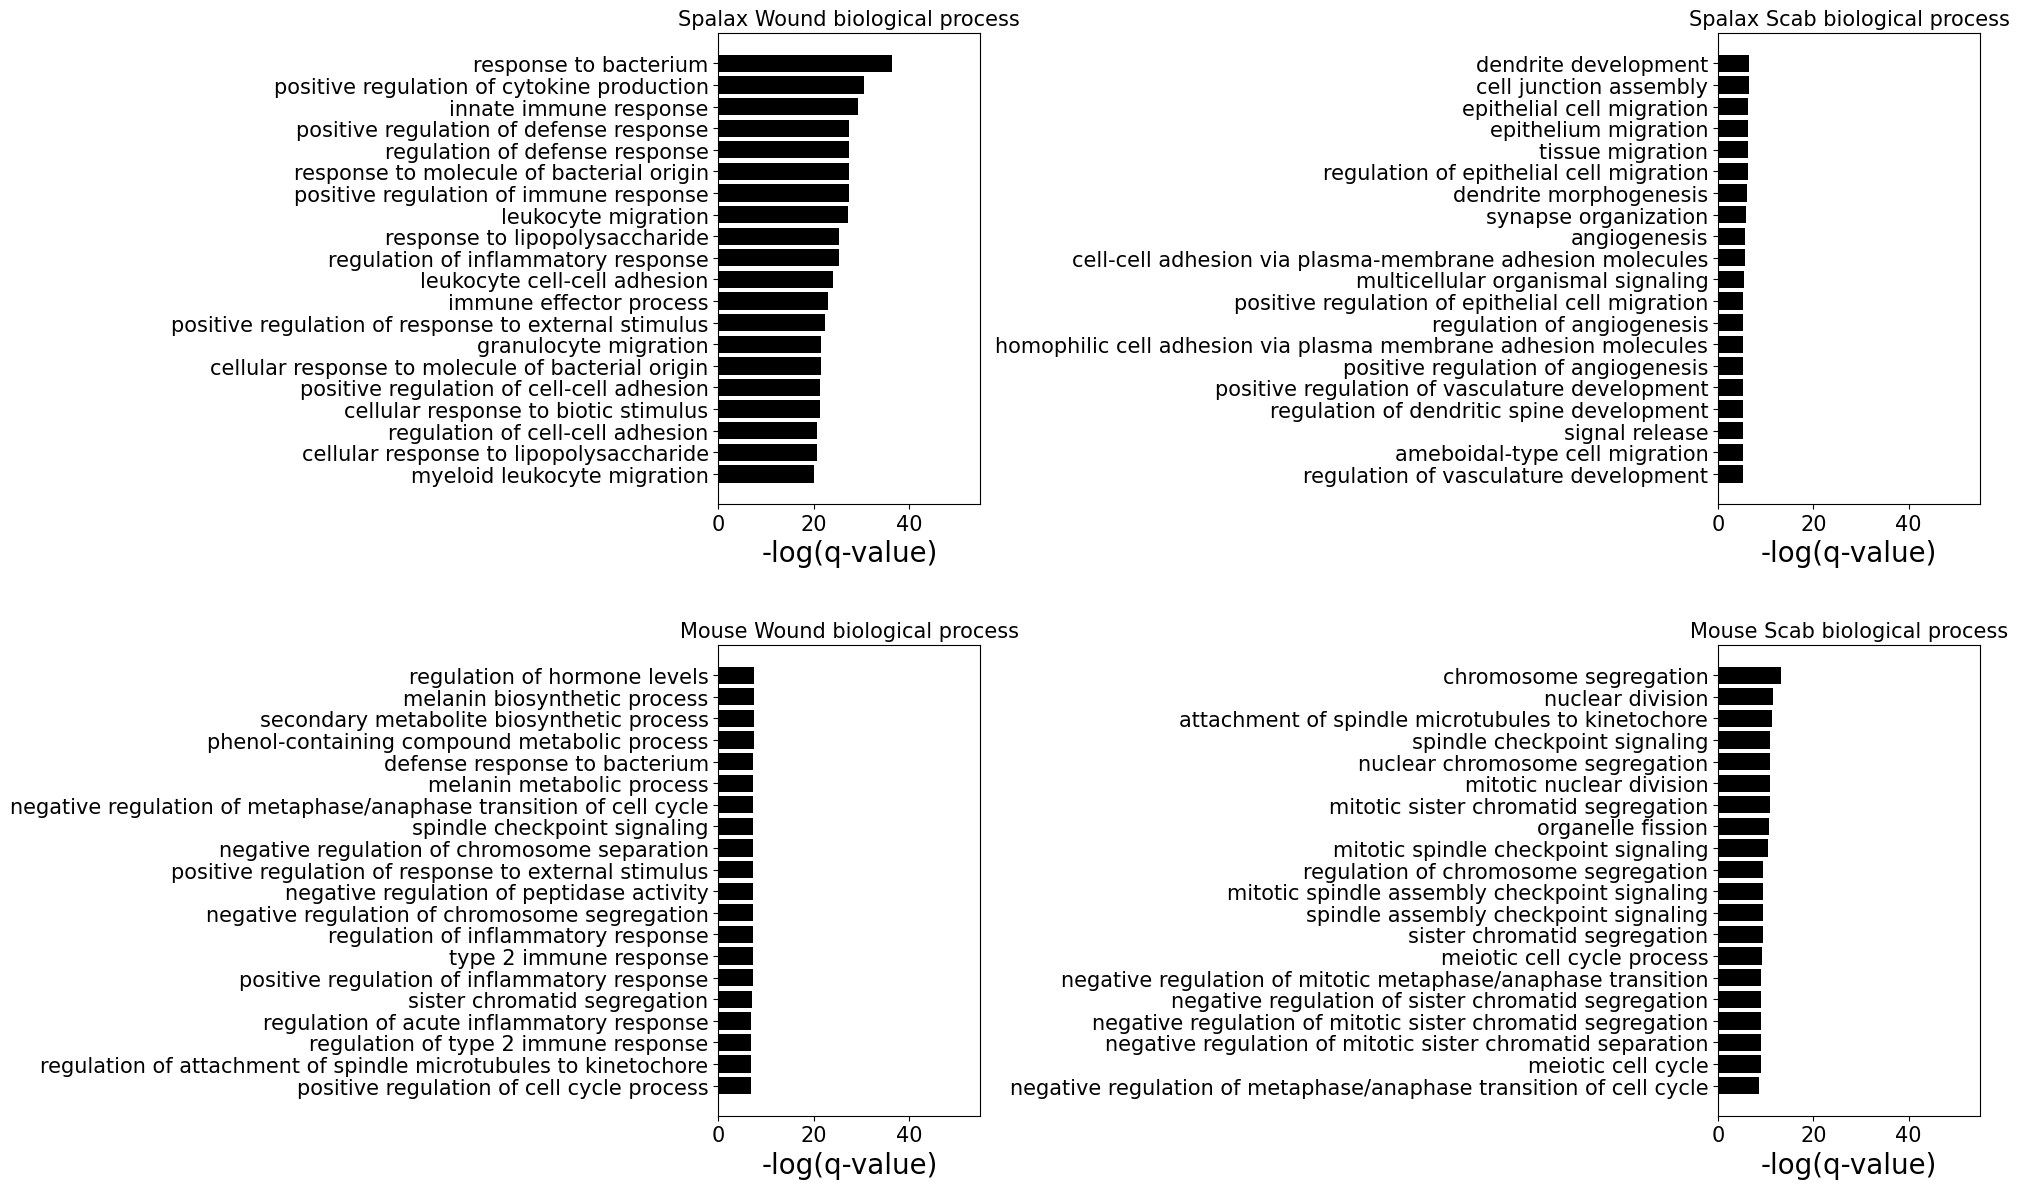

In [27]:
spalax_wound_bp = pd.read_csv("../entrezID/S.control-S.wound/GeneOntologyBPUp.csv")
spalax_wound_bp = spalax_wound_bp.drop(columns = ['Unnamed: 0'])
spalax_wound_bp = filter_by_qvalue(spalax_wound_bp)
spalax_scab_bp = pd.read_csv("../entrezID/S.control-S.scar/GeneOntologyBPUp.csv")
spalax_scab_bp = spalax_scab_bp.drop(columns = ['Unnamed: 0'])
spalax_scab_bp = filter_by_qvalue(spalax_scab_bp)

spalax_wound_bp_scab = filter_scab_q_value(spalax_scab_bp, spalax_wound_bp)
spalax_wound_bp_scab = reindex_df(spalax_wound_bp[["Description", "qvalue"]].head(10), spalax_wound_bp_scab)
print("\n")
print(spalax_wound_bp[["Description", "qvalue"]].head(10))
print(spalax_wound_bp_scab.head(10))


mouse_wound_bp = pd.read_csv("../entrezID/MM.control-M.wound/GeneOntologyBPUp.csv")
mouse_wound_bp = mouse_wound_bp.drop(columns = ['Unnamed: 0'])
mouse_wound_bp = filter_by_qvalue(mouse_wound_bp)
mouse_scab_bp = pd.read_csv("../entrezID/MM.control-M.scar/GeneOntologyBPUp.csv")
mouse_scab_bp = mouse_scab_bp.drop(columns = ['Unnamed: 0'])
mouse_scab_bp = filter_by_qvalue(mouse_scab_bp)

mouse_wound_bp_scab = filter_scab_q_value(mouse_scab_bp, mouse_wound_bp)
mouse_wound_bp_scab = reindex_df(mouse_wound_bp[["Description", "qvalue"]].head(20), mouse_wound_bp_scab)
print("\n")
print(mouse_wound_bp[["Description", "qvalue"]].head(10))
print(mouse_wound_bp_scab.head(10))

# Create a 2x2 subplot figure
fig, axs = plt.subplots(2, 2, figsize=(20, 12))

# Plot each pathway intensity on its respective subplot
plot_pathway_intensity(axs[0, 0], spalax_wound_bp, 'Spalax Wound biological process')
plot_pathway_intensity(axs[0, 1], spalax_scab_bp, 'Spalax Scab biological process')
plot_pathway_intensity(axs[1, 0], mouse_wound_bp, 'Mouse Wound biological process')
plot_pathway_intensity(axs[1, 1], mouse_scab_bp, 'Mouse Scab biological process')

# Adjust layout for better spacing
plt.tight_layout()
plt.subplots_adjust(hspace=0.3)  # Increase the space between rows

# Show the plot
plt.show()

### Downregulated analysis



                                Description    qvalue
0  monocarboxylic acid biosynthetic process  0.000006
1              fatty acid metabolic process  0.000018
2           fatty acid biosynthetic process  0.000057
3                   lipid catabolic process  0.000074
4     monocarboxylic acid metabolic process  0.000079
5      carboxylic acid biosynthetic process  0.000170
6         organic acid biosynthetic process  0.000170
7       small molecule biosynthetic process  0.000387
8            sphingolipid metabolic process  0.002644
9   long-chain fatty acid metabolic process  0.002644
                                Description  qvalue
0  monocarboxylic acid biosynthetic process       0
1              fatty acid metabolic process       0
2           fatty acid biosynthetic process       0
3                   lipid catabolic process       0
4     monocarboxylic acid metabolic process       0
5      carboxylic acid biosynthetic process       0
6         organic acid biosynthetic proc

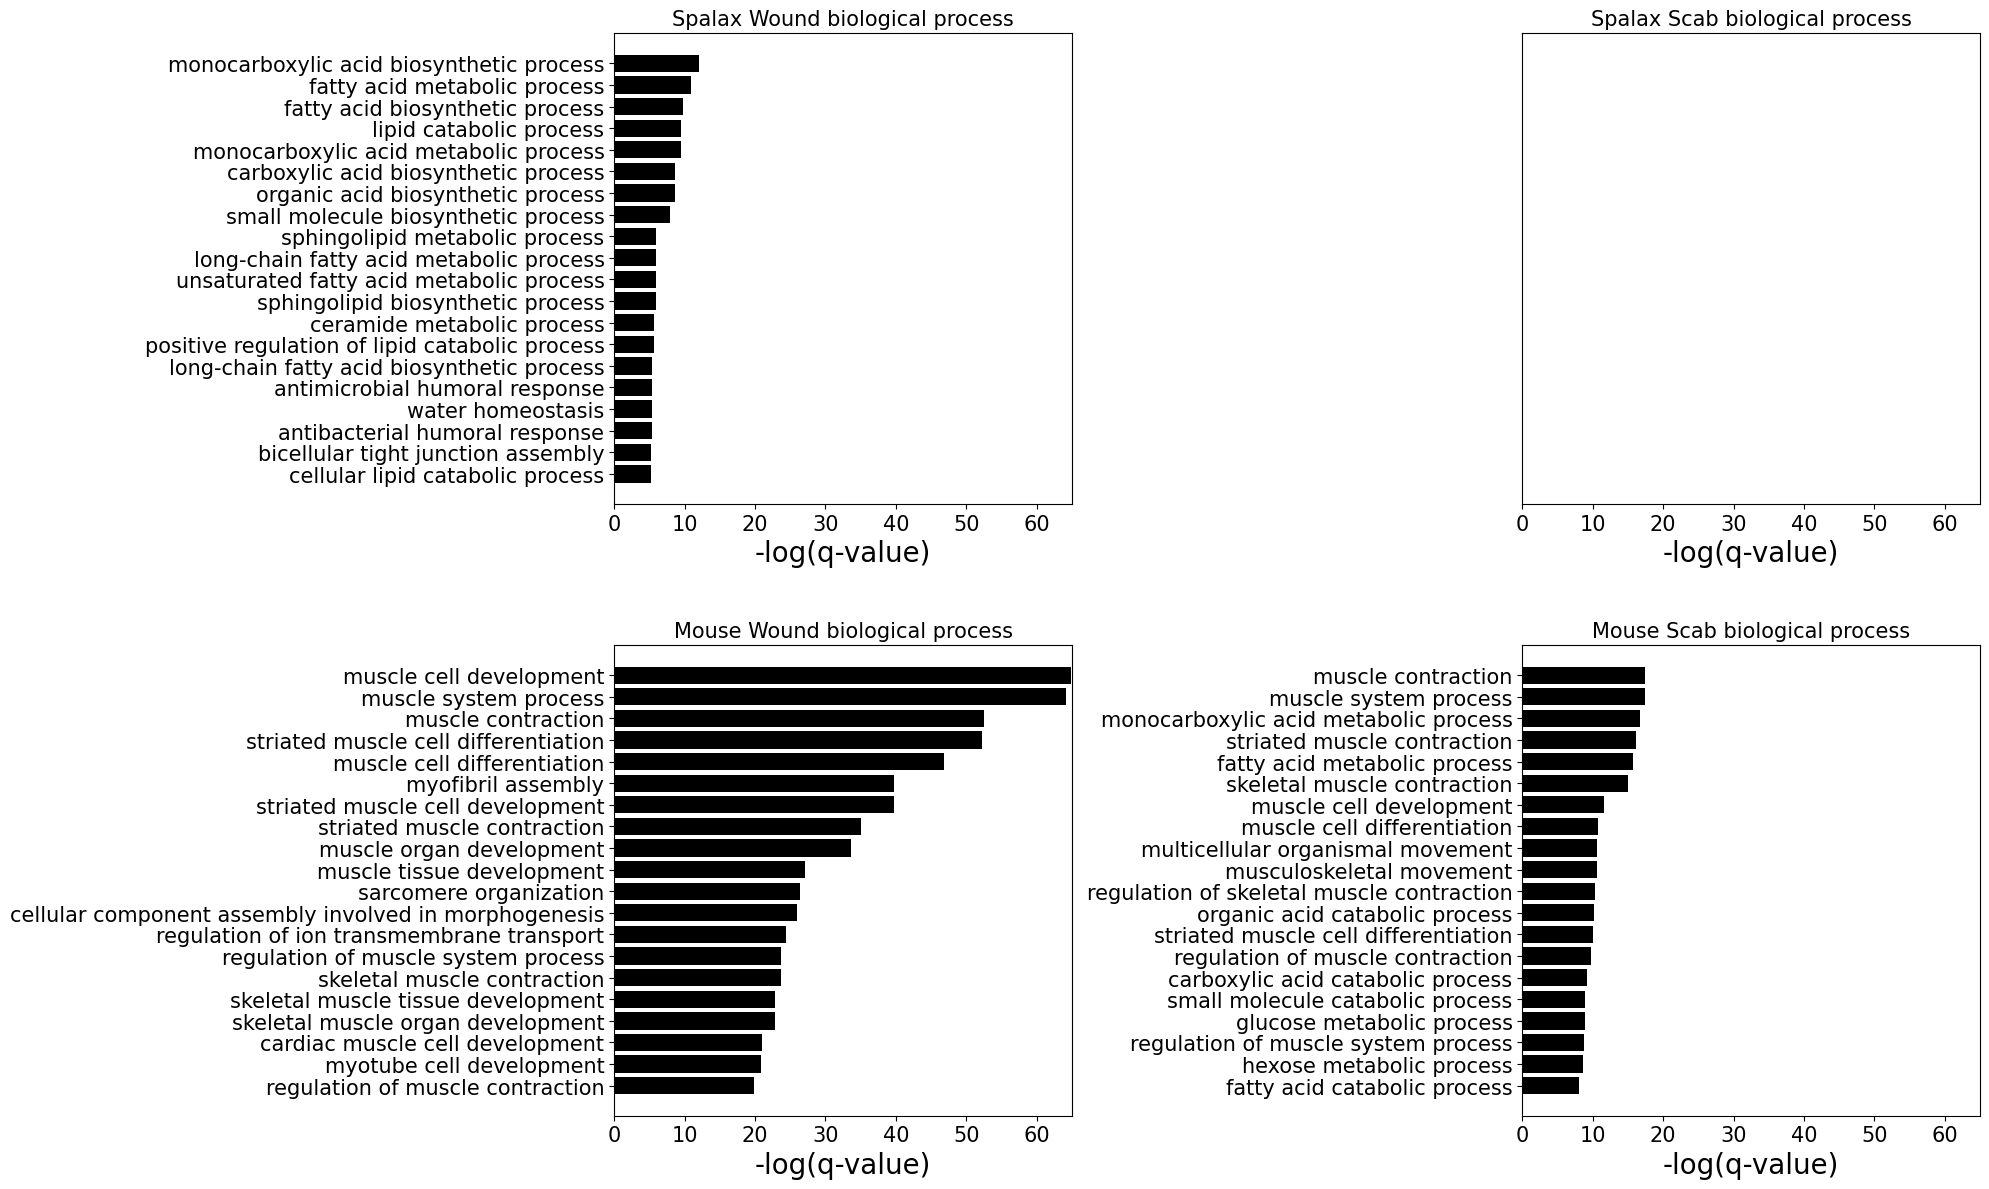

In [63]:
def plot_pathway_intensity(ax, timepoint, title):
    pathways = timepoint.iloc[0:20][['Description', 'qvalue']]
    pathways['Description'] = [p.split(' - Mus musculus (house mouse)')[0] for p in pathways['Description'].values]
    pathways['qvalue'] = -np.log(pathways['qvalue'])

    y_pos = np.arange(len(pathways))[::-1]
    ax.barh(y_pos, pathways.qvalue, align='center', color='black')
    ax.set_yticks(y_pos)
    ax.set_yticklabels(pathways.Description, fontsize=15)  # Increase y tick label size
    ax.set_title(title, fontsize=15)
    ax.set_xlim(0, 65)
    ax.set_xlabel('-log(q-value)', fontsize=20)
    ax.tick_params(axis='x', labelsize=15)  # Increase x tick label size
    
spalax_wound_bp = pd.read_csv("../entrezID/S.control-S.wound/GeneOntologyBPDown.csv")
spalax_wound_bp = spalax_wound_bp.drop(columns = ['Unnamed: 0'])
spalax_wound_bp = filter_by_qvalue(spalax_wound_bp)
spalax_scab_bp = pd.read_csv("../entrezID/S.control-S.scar/GeneOntologyBPDown.csv")
spalax_scab_bp = spalax_scab_bp.drop(columns = ['Unnamed: 0'])
spalax_scab_bp = filter_by_qvalue(spalax_scab_bp)

spalax_wound_bp_scab = filter_scab_q_value(spalax_scab_bp, spalax_wound_bp)
spalax_wound_bp_scab = reindex_df(spalax_wound_bp[["Description", "qvalue"]].head(10), spalax_wound_bp_scab)
print("\n")
print(spalax_wound_bp[["Description", "qvalue"]].head(10))
print(spalax_wound_bp_scab.head(10))


mouse_wound_bp = pd.read_csv("../entrezID/MM.control-M.wound/GeneOntologyBPDown.csv")
mouse_wound_bp = mouse_wound_bp.drop(columns = ['Unnamed: 0'])
mouse_wound_bp = filter_by_qvalue(mouse_wound_bp)
mouse_scab_bp = pd.read_csv("../entrezID/MM.control-M.scar/GeneOntologyBPDown.csv")
mouse_scab_bp = mouse_scab_bp.drop(columns = ['Unnamed: 0'])
mouse_scab_bp = filter_by_qvalue(mouse_scab_bp)

mouse_wound_bp_scab = filter_scab_q_value(mouse_scab_bp, mouse_wound_bp)
mouse_wound_bp_scab = reindex_df(mouse_wound_bp[["Description", "qvalue"]].head(20), mouse_wound_bp_scab)
print("\n")
print(mouse_wound_bp[["Description", "qvalue"]].head(10))
print(mouse_wound_bp_scab.head(10))

# Create a 2x2 subplot figure
fig, axs = plt.subplots(2, 2, figsize=(20, 12))

# Plot each pathway intensity on its respective subplot
plot_pathway_intensity(axs[0, 0], spalax_wound_bp, 'Spalax Wound biological process')
plot_pathway_intensity(axs[0, 1], spalax_scab_bp, 'Spalax Scab biological process')
plot_pathway_intensity(axs[1, 0], mouse_wound_bp, 'Mouse Wound biological process')
plot_pathway_intensity(axs[1, 1], mouse_scab_bp, 'Mouse Scab biological process')

# Adjust layout for better spacing
plt.tight_layout()
plt.subplots_adjust(hspace=0.3)  # Increase the space between rows

# Show the plot
plt.show()